# Practice 11 — Object Detection and Segmentation

**Goal:** run a pretrained detector and a segmentation model, read what they return — *where*, not only *what* — and score the detector with mAP.

| Task | Output per object | Numbers per object |
|:---|:---|:---|
| Classification | one label for the whole image | 1 class index |
| Object detection | one axis-aligned box | 4 coordinates + class + confidence |
| Instance segmentation | one per-pixel mask | a 0/1 grid + class + confidence |

- Nothing is trained here → the weights arrive pretrained on the 80 COCO classes

---
## Step 0. Setup

- `ultralytics` → the YOLO models with their `predict` and `val` methods
- A path given to `YOLO(...)` → the weights are downloaded there, not into the working directory

In [1]:
import subprocess
import sys

try:
    import ultralytics
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'ultralytics'], check=True)
    import ultralytics

print(f'ultralytics {ultralytics.__version__}')

ultralytics 8.4.193


In [2]:
import urllib.request
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
from ultralytics import YOLO

np.random.seed(42)
torch.manual_seed(42)

# the weights and the sample images are saved under these two folders
BUILD = Path('build')
DATA = Path('data')
BUILD.mkdir(exist_ok=True)
DATA.mkdir(exist_ok=True)

print(f'GPU available : {torch.cuda.is_available()}')

GPU available : True


image shape : (1380, 2070, 3)   height, width, channels


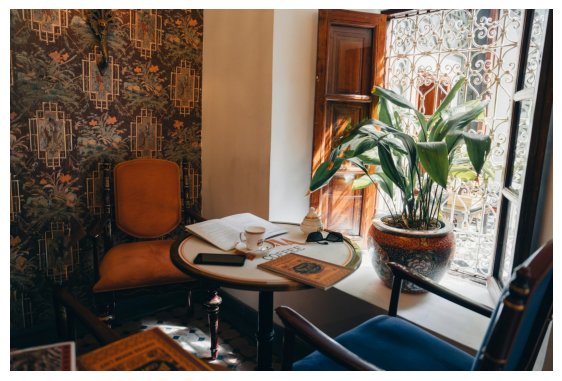

In [3]:
image_path = DATA / 'detection_sample.jpg'
if not image_path.exists():
    urllib.request.urlretrieve(
        'https://images.unsplash.com/photo-1760681557777-bfac1f18cf90'
        '?ixlib=rb-4.1.0&auto=format&fit=crop&q=80&w=2070', image_path)

second_image_path = DATA / 'bus.jpg'
if not second_image_path.exists():
    urllib.request.urlretrieve('https://ultralytics.com/images/bus.jpg', second_image_path)

image = np.array(Image.open(image_path).convert('RGB'))
print(f'image shape : {image.shape}   height, width, channels')

plt.figure(figsize=(7, 5))
plt.imshow(image)
plt.axis('off')
plt.show()

---
## Step 1. Running the Detector

- `yolo11n` → the smallest YOLO11, already knows the 80 COCO classes
- `conf=0.25` → drops detections below 25% confidence
- `predict` returns a list → one `Results` object per input image

In [4]:
detection_model = YOLO(str(BUILD / 'yolo11n.pt'))
detection_results = detection_model.predict(source=str(image_path), conf=0.25, verbose=False)

print(f'results returned : {len(detection_results)}   one per input image')

detection_result = detection_results[0]
print(f'objects found    : {len(detection_result.boxes)}')

results returned : 1   one per input image
objects found    : 6


---
## Step 2. What Is Inside `result.boxes`

- One row per detected object in every attribute

| Attribute | Shape | Meaning |
|:---|:---|:---|
| `boxes.xyxy` | (N, 4) | corners in pixels, `(x1, y1, x2, y2)` |
| `boxes.conf` | (N,) | confidence |
| `boxes.cls` | (N,) | class index, stored as a float → `int()` before `result.names[...]` |

In [5]:
print(f'boxes.xyxy : {tuple(detection_result.boxes.xyxy.shape)}')
print(f'boxes.conf : {tuple(detection_result.boxes.conf.shape)}')
print(f'boxes.cls  : {tuple(detection_result.boxes.cls.shape)}')
print(f'names      : {len(detection_result.names)} class names')
print()

for index in range(len(detection_result.boxes)):
    class_index = int(detection_result.boxes.cls[index])
    confidence = float(detection_result.boxes.conf[index])
    x1, y1, x2, y2 = detection_result.boxes.xyxy[index].cpu().numpy()
    print(f'{detection_result.names[class_index]:<14s} conf={confidence:.3f}  '
          f'x1={x1:7.1f} y1={y1:7.1f} x2={x2:7.1f} y2={y2:7.1f}')

boxes.xyxy : (6, 4)
boxes.conf : (6,)
boxes.cls  : (6,)
names      : 80 class names

chair          conf=0.833  x1= 1016.6 y1=  871.4 x2= 2069.0 y2= 1365.0
potted plant   conf=0.800  x1= 1187.1 y1=  248.5 x2= 1851.2 y2= 1066.7
cup            conf=0.761  x1=  886.8 y1=  824.1 x2=  975.6 y2=  917.8
chair          conf=0.711  x1=  317.1 y1=  567.0 x2=  715.7 y2= 1171.8
dining table   conf=0.563  x1=  630.4 y1=  770.6 x2= 1358.1 y2= 1362.8
chair          conf=0.412  x1=  161.9 y1= 1038.8 x2=  749.1 y2= 1367.1


---
## Step 3. Drawing the Boxes

- `result.plot()` → annotated image in **BGR** order, so the channels are reversed for matplotlib
- Right panel → the same boxes drawn from `boxes.xyxy` by hand

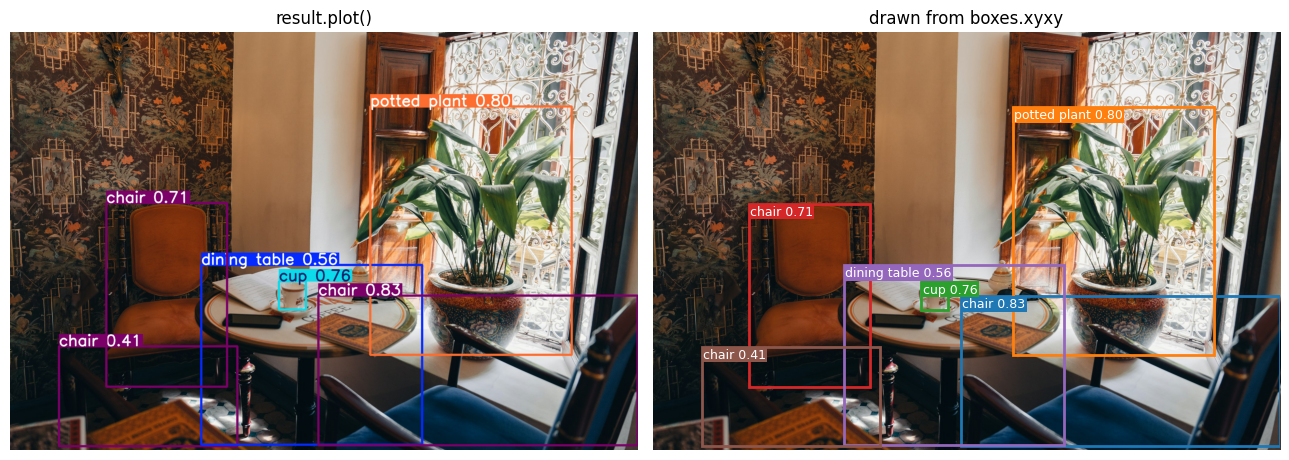

In [6]:
annotated_image = detection_result.plot()[:, :, ::-1]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].imshow(annotated_image)
axes[0].set_title('result.plot()')
axes[0].axis('off')

axes[1].imshow(image)
for index in range(len(detection_result.boxes)):
    class_index = int(detection_result.boxes.cls[index])
    confidence = float(detection_result.boxes.conf[index])
    x1, y1, x2, y2 = detection_result.boxes.xyxy[index].cpu().numpy()
    instance_color = plt.cm.tab10(index % 10)
    axes[1].add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1,
                                fill=False, edgecolor=instance_color, linewidth=2))
    # the label sits inside the top edge, so a box touching y=0 keeps its text on the image
    axes[1].text(x1 + 4, y1 + 4, f'{detection_result.names[class_index]} {confidence:.2f}',
                 color='white', fontsize=9, va='top', ha='left', clip_on=True,
                 bbox=dict(facecolor=instance_color, edgecolor='none', pad=1))
axes[1].set_title('drawn from boxes.xyxy')
axes[1].axis('off')

plt.tight_layout()
plt.show()

- Same rectangles in both panels → `plot()` is convenient, the loop shows what the coordinates mean

---
## Step 4. The Confidence Threshold

- Only `conf` changes between the two calls → each object is listed with its confidence

In [7]:
result_25 = detection_model.predict(source=str(image_path), conf=0.25, verbose=False)[0]
result_50 = detection_model.predict(source=str(image_path), conf=0.50, verbose=False)[0]

labels_25 = []
for index in range(len(result_25.boxes)):
    class_name = result_25.names[int(result_25.boxes.cls[index])]
    confidence = float(result_25.boxes.conf[index])
    labels_25.append(f'{class_name} {confidence:.2f}')

labels_50 = []
for index in range(len(result_50.boxes)):
    class_name = result_50.names[int(result_50.boxes.cls[index])]
    confidence = float(result_50.boxes.conf[index])
    labels_50.append(f'{class_name} {confidence:.2f}')

print(f'conf=0.25 : {len(labels_25)} objects  ' + ', '.join(labels_25))
print(f'conf=0.50 : {len(labels_50)} objects  ' + ', '.join(labels_50))

conf=0.25 : 6 objects  chair 0.83, potted plant 0.80, cup 0.76, chair 0.71, dining table 0.56, chair 0.41
conf=0.50 : 5 objects  chair 0.83, potted plant 0.80, cup 0.76, chair 0.71, dining table 0.56


- Detections come sorted by confidence → the list shortens from the bottom: `chair` 0.41 drops out at `conf=0.50`

---
## Step 5. NMS

- The detector proposes many boxes → several pass `conf` on the same object
- NMS (non-maximum suppression) keeps the most confident box of a class and removes the others overlapping it by IoU above `iou`, a `predict` argument with default 0.7
- `iou=1.0` → nothing is removed: the raw list behind Step 1

iou=1.0 (NMS off) : 52 boxes
iou=0.7 (default) :  6 boxes


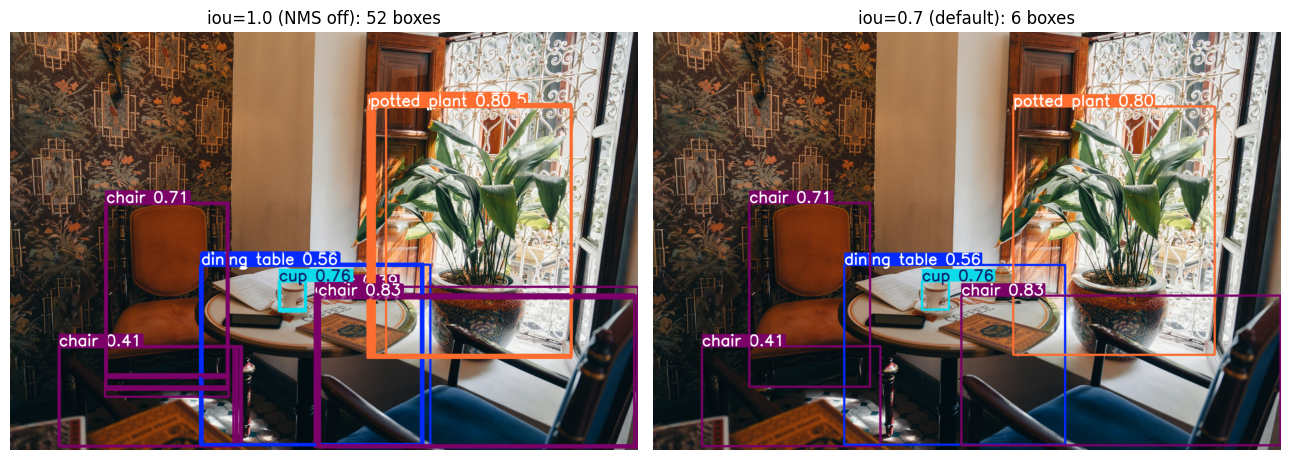

In [8]:
raw_result = detection_model.predict(source=str(image_path), conf=0.25, iou=1.0, verbose=False)[0]

print(f'iou=1.0 (NMS off) : {len(raw_result.boxes):2d} boxes')
print(f'iou=0.7 (default) : {len(detection_result.boxes):2d} boxes')

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].imshow(raw_result.plot()[:, :, ::-1])
axes[0].set_title(f'iou=1.0 (NMS off): {len(raw_result.boxes)} boxes')

axes[1].imshow(detection_result.plot()[:, :, ::-1])
axes[1].set_title(f'iou=0.7 (default): {len(detection_result.boxes)} boxes')

for panel_axis in axes:
    panel_axis.axis('off')

plt.tight_layout()
plt.show()

- 52 raw boxes → 6: every chair, cup, plant and table collapses to its most confident box
- Left → what `conf` alone leaves; right → what `predict` returns

---
## Step 6. Scoring the Detector: mAP

- Scoring needs labelled boxes → `coco8`, 8 COCO images with labels, 4 for validation
- A YOLO dataset = `images/` and `labels/` with matching file names; one `.txt` per image, one line per object: `class cx cy w h`, centre and size over the image size
- The same three cells score any dataset in this layout, yours included

In [9]:
import zipfile

coco8_dir = DATA / 'coco8'
if not coco8_dir.exists():
    urllib.request.urlretrieve(
        'https://github.com/ultralytics/assets/releases/download/v0.0.0/coco8.zip', BUILD / 'coco8.zip')
    with zipfile.ZipFile(BUILD / 'coco8.zip') as archive:
        archive.extractall(DATA)

for folder in ['images/train', 'images/val', 'labels/train', 'labels/val']:
    n_files = len(list((coco8_dir / folder).glob('*')))
    print(f'coco8/{folder:<13s} {n_files} files')

label_path = coco8_dir / 'labels' / 'val' / '000000000036.txt'
print()
print(label_path.name)
print(label_path.read_text().strip())

coco8/images/train  4 files
coco8/images/val    4 files
coco8/labels/train  4 files
coco8/labels/val    4 files

000000000036.txt
25 0.475759 0.414523 0.951518 0.672422
0 0.671279 0.617945 0.645759 0.726859


- Two lines → two objects: class 25 = `umbrella`, class 0 = `person` in COCO's numbering; `val()` draws them below

- The library reads a dataset through a yaml file → where the `train` and `val` images are (labels are found by swapping `images` for `labels`) and what each class index means
- `names` → the 80 COCO classes in the model's order here; your own dataset lists its own

In [10]:
coco8_yaml_path = (DATA / 'coco8.yaml').resolve()

# the two folders are written relative to the folder this file sits in
with open(coco8_yaml_path, 'w', encoding='utf-8') as yaml_file:
    yaml_file.write('train: coco8/images/train\n')
    yaml_file.write('val: coco8/images/val\n')
    yaml_file.write('names:\n')
    for class_index, class_name in detection_model.names.items():
        yaml_file.write(f'  {class_index}: {class_name}\n')

# the first lines; names run on to 79
for line in coco8_yaml_path.read_text().splitlines()[:6]:
    print(line)

train: coco8/images/train
val: coco8/images/val
names:
  0: person
  1: bicycle
  2: car


- `val()` scores the detector on the `val` images → precision, recall and mAP per class
- mAP@50 → a match needs IoU ≥ 0.5; mAP@50-95 → averaged over IoU 0.5 to 0.95, rewarding tight boxes

In [11]:
coco_metrics = detection_model.val(data=str(coco8_yaml_path))

print()
print(f'mAP@50    : {coco_metrics.box.map50:.3f}')
print(f'mAP@50-95 : {coco_metrics.box.map:.3f}')

Ultralytics 8.4.193  Python-3.11.13 torch-2.11.0+cu128 CUDA:0 (NVIDIA TITAN RTX, 24576MiB)


YOLO11n summary (fused): 100 layers, 2,616,248 parameters, 0 gradients, 6.5 GFLOPs


val: Fast image access  (ping: 0.1±0.0 ms, read: 213.0±113.8 MB/s, size: 54.0 KB)


val: Scanning D:\Main\00_Research\00_Python\00_Lecture\03_Advanced_AI-ME_Graduate\data\coco8\labels\val... 4 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 4/4 723.8it/s 0.0s

val: New cache created: D:\Main\00_Research\00_Python\00_Lecture\03_Advanced_AI-ME_Graduate\data\coco8\labels\val.cache


...

              umbrella          1          1      0.569          1      0.995      0.995


          potted plant          1          1      0.847          1      0.995      0.895


Speed: 0.7ms preprocess, 14.8ms inference, 0.0ms loss, 2.2ms postprocess per image


Results saved to D:\Main\00_Research\00_Python\00_Lecture\03_Advanced_AI-ME_Graduate\runs\detect\val



mAP@50    : 0.854
mAP@50-95 : 0.631


- `all` row → 17 labelled objects in 4 images; mAP = the mean over the six classes with labels, `elephant` (2 labels) weighing as much as `person` (10)
- 0.631 < 0.854 → the same boxes must also match at IoU 0.75 or 0.95
- 4 images → a demonstration, not a benchmark; COCO val has 5,000

- `val()` saves pictures in the folder printed last → the labels it read, its predictions, and the precision–recall curve whose area per class is the AP

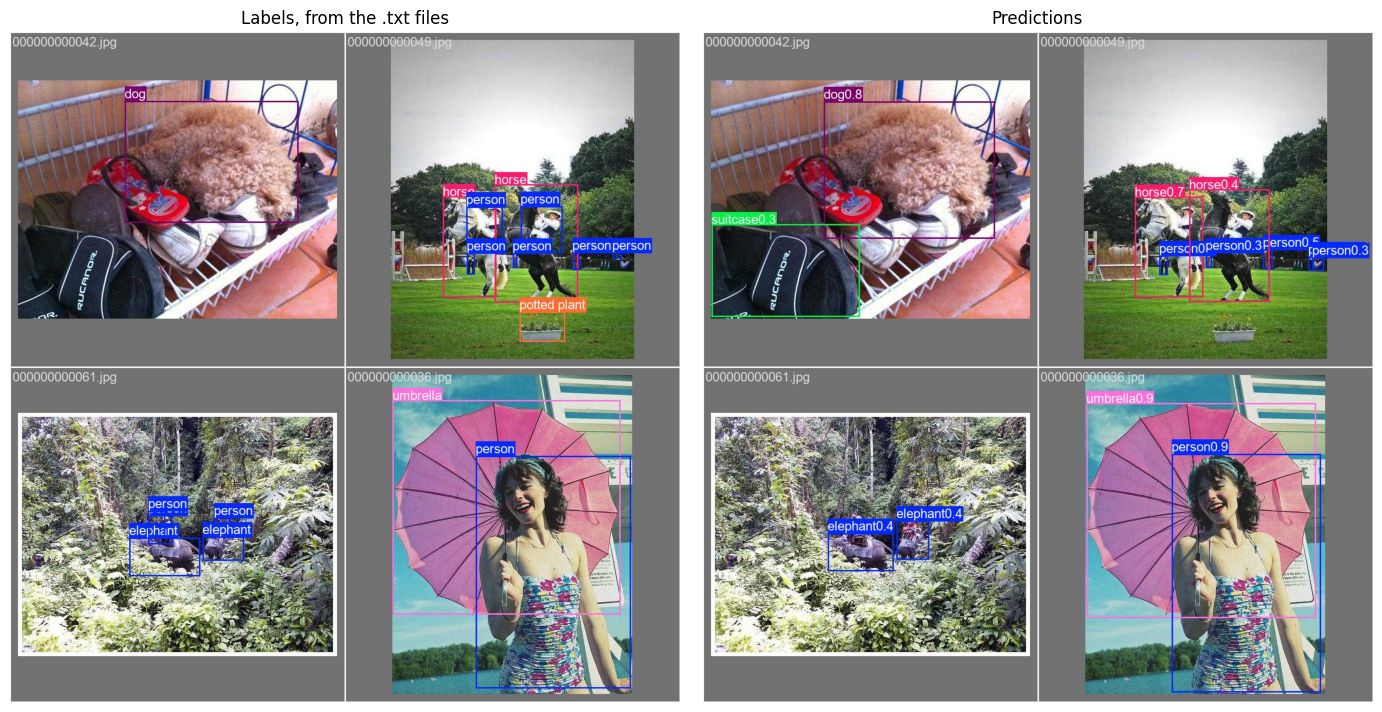

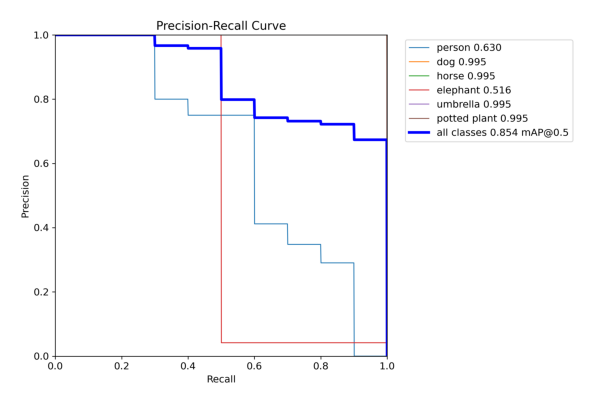

In [12]:
val_dir = Path(coco_metrics.save_dir)

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

axes[0].imshow(Image.open(val_dir / 'val_batch0_labels.jpg'))
axes[0].set_title('Labels, from the .txt files')

axes[1].imshow(Image.open(val_dir / 'val_batch0_pred.jpg'))
axes[1].set_title('Predictions')

for panel_axis in axes:
    panel_axis.axis('off')

plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.imshow(Image.open(val_dir / 'BoxPR_curve.png'))
plt.axis('off')
plt.show()

---
## Step 7. The Segmentation Model

- Everything the detector returns, plus one mask per object
- `retina_masks=True` → masks at the image size (the default is the smaller size the model ran at)

| Attribute | Shape | Meaning |
|:---|:---|:---|
| `boxes.xyxy` · `conf` · `cls` | as in Step 2 | one box per object |
| `masks.data` | (N, H, W) | one 0/1 grid per object, 1 inside |

In [13]:
segmentation_model = YOLO(str(BUILD / 'yolo11n-seg.pt'))
segmentation_result = segmentation_model.predict(source=str(image_path), conf=0.25,
                                                 retina_masks=True, verbose=False)[0]

print(f'objects found : {len(segmentation_result.boxes)}')
print(f'boxes.xyxy    : {tuple(segmentation_result.boxes.xyxy.shape)}')
print(f'masks.data    : {tuple(segmentation_result.masks.data.shape)}')
print()

for index in range(len(segmentation_result.boxes)):
    class_index = int(segmentation_result.boxes.cls[index])
    confidence = float(segmentation_result.boxes.conf[index])
    print(f'{segmentation_result.names[class_index]:<14s} conf={confidence:.3f}')

objects found : 7
boxes.xyxy    : (7, 4)
masks.data    : (7, 1380, 2070)

chair          conf=0.882
cup            conf=0.846
potted plant   conf=0.834
chair          conf=0.728
remote         conf=0.295
chair          conf=0.279
dining table   conf=0.266


- 7 objects, one more than the detector's 6 → another weights file, slightly different detections (`remote` 0.295)
- `masks.data` (7, 1380, 2070) → one grid per object, each the size of the image

- One mask per object, not per class → each chair in the list above has its own mask

| Task | One output covers |
|:---|:---|
| Semantic segmentation | every pixel of a class, as a single region |
| Instance segmentation | every pixel of one object, one mask per object |

- The segmentation model here → instance segmentation

---
## Step 8. Drawing the Masks

- Third panel → one `masks.data` grid; `result.plot()` lays all of them on the image

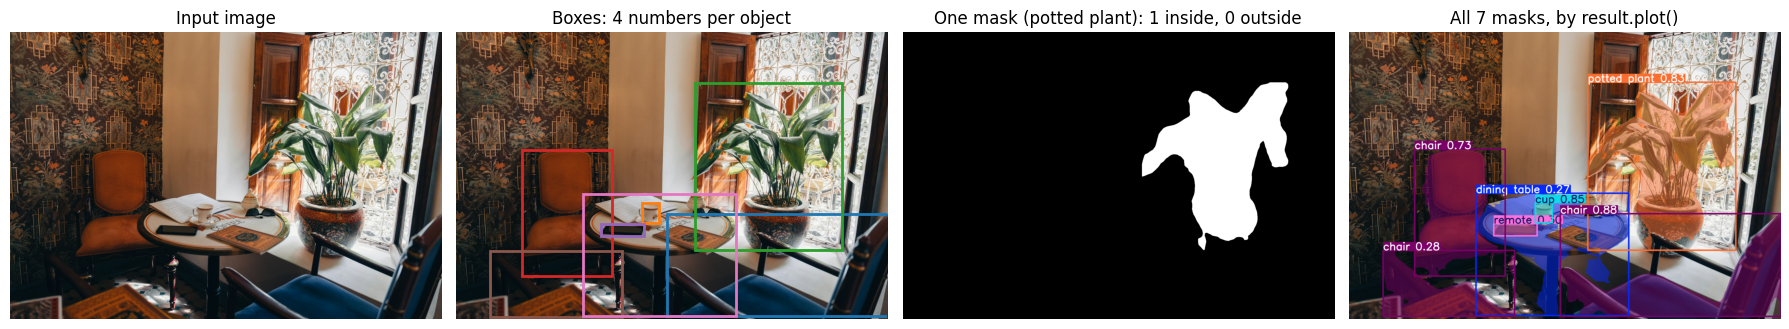

In [14]:
mask_index = 2
mask_class = segmentation_result.names[int(segmentation_result.boxes.cls[mask_index])]
one_mask = segmentation_result.masks.data[mask_index].cpu().numpy()

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))

axes[0].imshow(image)
axes[0].set_title('Input image')
axes[0].axis('off')

axes[1].imshow(image)
for index in range(len(segmentation_result.boxes)):
    x1, y1, x2, y2 = segmentation_result.boxes.xyxy[index].cpu().numpy()
    axes[1].add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False,
                                edgecolor=plt.cm.tab10(index % 10), linewidth=2))
axes[1].set_title('Boxes: 4 numbers per object')
axes[1].axis('off')

axes[2].imshow(one_mask, cmap='gray')
axes[2].set_title(f'One mask ({mask_class}): 1 inside, 0 outside')
axes[2].axis('off')

axes[3].imshow(segmentation_result.plot()[:, :, ::-1])
axes[3].set_title(f'All {len(segmentation_result.boxes)} masks, by result.plot()')
axes[3].axis('off')

plt.tight_layout()
plt.show()

- Box → where an object is; mask → which pixels are the object
- `plot()` colours by class → the chairs share one colour, yet each has its own mask

---
## Step 9. What the Mask Buys You

- A mask gives the object's pixel count, a box only its extent
- Mask pixels / box pixels → how much of its box the object fills

In [15]:
print('object          mask pixels   box pixels   fill')
for index in range(len(segmentation_result.boxes)):
    class_index = int(segmentation_result.boxes.cls[index])
    x1, y1, x2, y2 = segmentation_result.boxes.xyxy[index].cpu().numpy()
    box_pixels = (x2 - x1) * (y2 - y1)
    mask_pixels = float(segmentation_result.masks.data[index].cpu().numpy().sum())
    fill = mask_pixels / box_pixels
    print(f'{segmentation_result.names[class_index]:<14s} {mask_pixels:11.0f} {box_pixels:12.0f}   {fill:.3f}')

object          mask pixels   box pixels   fill
chair               201427       520377   0.387
cup                   6389         7696   0.830
potted plant        279529       570453   0.490
chair               161190       264000   0.611
remote               10547        12172   0.866
chair               100786       199132   0.506
dining table        164839       428598   0.385


- Compact objects fill their box (`cup` 0.83, `remote` 0.87); wide or hollow ones do not (chairs, plant, table 0.38–0.61)
- Low fill → the box is mostly background

---
## Step 10. The Same Two Calls on Another Image

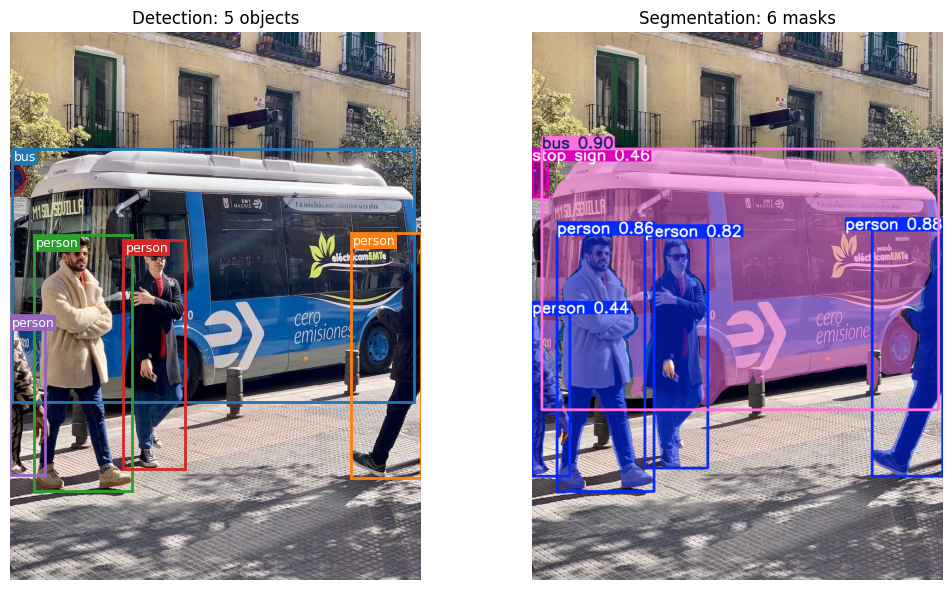

In [16]:
second_image = np.array(Image.open(second_image_path).convert('RGB'))
second_detection = detection_model.predict(source=str(second_image_path), conf=0.25, verbose=False)[0]
second_segmentation = segmentation_model.predict(source=str(second_image_path), conf=0.25,
                                                 retina_masks=True, verbose=False)[0]

fig, axes = plt.subplots(1, 2, figsize=(11, 6))

axes[0].imshow(second_image)
for index in range(len(second_detection.boxes)):
    class_index = int(second_detection.boxes.cls[index])
    x1, y1, x2, y2 = second_detection.boxes.xyxy[index].cpu().numpy()
    instance_color = plt.cm.tab10(index % 10)
    axes[0].add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1,
                                fill=False, edgecolor=instance_color, linewidth=2))
    axes[0].text(x1 + 4, y1 + 4, second_detection.names[class_index],
                 color='white', fontsize=9, va='top', ha='left', clip_on=True,
                 bbox=dict(facecolor=instance_color, edgecolor='none', pad=1))
axes[0].set_title(f'Detection: {len(second_detection.boxes)} objects')
axes[0].axis('off')

axes[1].imshow(second_segmentation.plot()[:, :, ::-1])
axes[1].set_title(f'Segmentation: {len(second_segmentation.boxes)} masks')
axes[1].axis('off')

plt.tight_layout()
plt.show()

- 5 boxes, 6 masks → the extra mask is the round sign at the left edge, labelled `stop sign` at 0.46, the nearest COCO class

---
## Summary

| Result | Holds | Note |
|:---|:---|:---|
| Detection | `boxes.xyxy` · `conf` · `cls`, one row per object | `conf` drops weak detections |
| NMS | `iou` threshold, default 0.7 | duplicates collapse to the most confident box |
| mAP | `val()` on a yaml → `images/` + `labels/` | @50 loose match, @50-95 tight boxes too |
| Segmentation | the same, plus `masks.data` | `retina_masks=True` → grids at the image size |

- Mask pixels / box pixels → how much of the box the object fills

---
## Exercises

1. `conf=0.7`, rerun the detection listing — which objects disappear, and what were their confidences?
2. Rerun `val()` with `conf=0.5` — does mAP@50 rise or fall, and why?
3. Draw only the object with the largest mask area, using the mask pixel counts from Step 9.

In [17]:
# Write your code here